# EDA Student Preformance Analysis

#### import libraries

In [2]:
import pandas as pd
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns

#### Load cleaned dataset

In [3]:
df = pd.read_csv("../data/processed/cleaned_student_sleep_screen_time_academic_performance.csv")

#### first look

In [22]:
pd.set_option('display.max_columns', None)
print(df.columns)
df.head()

Index(['student_id', 'age', 'gender', 'year_of_study', 'major_category',
       'residence_type', 'chronotype', 'avg_bedtime_hour',
       'avg_sleep_hours_weekday', 'weekend_sleep_delta_hours',
       'pre_sleep_screen_time_min', 'daily_screen_time_hours',
       'primary_device', 'device_free_before_bed', 'caffeine_drinks_per_day',
       'naps_per_week', 'sleep_quality_score', 'exercise_days_per_week',
       'energy_level', 'concentration_difficulty', 'weekly_study_hours',
       'class_attendance_percent', 'has_part_time_job', 'semester_type',
       'cgpa', 'daily_avg_study_hours', 'avg_badtime'],
      dtype='str')


,student_id,age,gender,year_of_study,major_category,residence_type,chronotype,avg_bedtime_hour,avg_sleep_hours_weekday,weekend_sleep_delta_hours,pre_sleep_screen_time_min,daily_screen_time_hours,primary_device,device_free_before_bed,caffeine_drinks_per_day,naps_per_week,sleep_quality_score,exercise_days_per_week,energy_level,concentration_difficulty,weekly_study_hours,class_attendance_percent,has_part_time_job,semester_type,cgpa,daily_avg_study_hours,avg_badtime
0,STU2001,21,Male,3,Humanities,With Family,Early Bird,22.3,7.6,2.0,12,7.1,Tablet,No,2,0,10.0,7,5.0,7.0,15.6,80.0,No,Spring,2.99,2.23,22:18
1,STU2002,20,Female,2,STEM,Dormitory,Intermediate,23.1,5.9,2.7,49,5.7,Laptop,Yes,1,3,7.0,3,6.0,7.0,17.5,78.9,No,Summer,2.88,2.50,23:06
2,STU2003,20,Male,4,Social Sciences,With Family,Intermediate,23.4,8.4,1.8,22,2.3,Smartphone,No,2,1,9.0,2,5.0,1.0,19.0,69.7,Yes,Spring,3.15,2.71,23:24
3,STU2004,22,Female,1,Humanities,Off-campus Apartment,Night Owl,0.9,5.1,2.4,32,4.8,Laptop,No,1,3,6.0,4,3.0,7.0,7.3,59.1,No,Fall,2.27,1.04,00:54
4,STU2005,23,Female,4,Social Sciences,Off-campus Apartment,Early Bird,23.4,5.9,2.0,27,4.5,Smartphone,No,4,2,7.0,6,8.0,3.0,23.6,79.9,No,Summer,2.74,3.37,23:24


## What analysis will I do?

To investigate whether academic performance is related to students' sleep, mobile screen time, energy and attention

#### column wise category (for easy to analyze)

| Category | Columns |
|---|---|
| ১. Student Identification | `student_id` |
| ২. Demographic & Academic Background | `age`, `gender`, `year_of_study`, `major_category`, `residence_type`, `semester_type` |
| ৩. Sleep Habits | `chronotype`, `avg_bedtime_hour`, `avg_sleep_hours_weekday`, `weekend_sleep_delta_hours`, `sleep_quality_score` |
| ৪. Screen Time & Device Usage | `pre_sleep_screen_time_min`, `daily_screen_time_hours`, `primary_device`, `device_free_before_bed` |
| ৫. Lifestyle & Well-being | `caffeine_drinks_per_day`, `naps_per_week`, `exercise_days_per_week`, `energy_level`, `concentration_difficulty` |
| ৬. Academic Performance & Study Habits | `weekly_study_hours`, `class_attendance_percent`, `has_part_time_job`, `cgpa` |

In [15]:
df['daily_avg_study_hours'] = round(df['weekly_study_hours'] / 7, 2)


#### Which category of students are more in the academy?

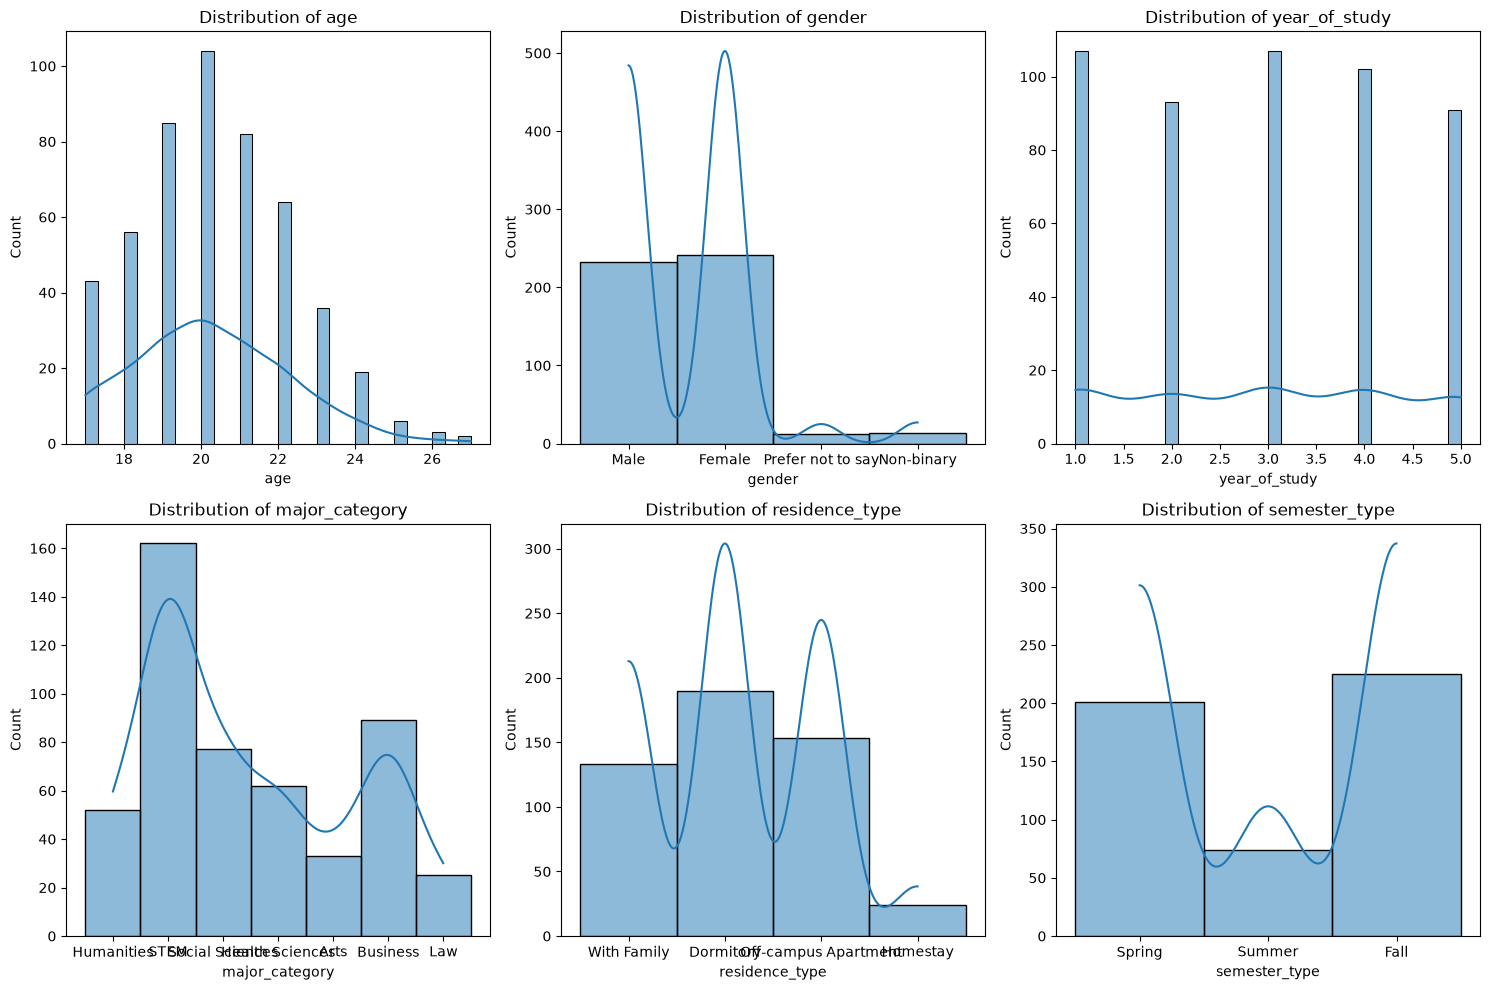

In [5]:

dab_col = ['age', 'gender', 'year_of_study', 'major_category', 'residence_type', 'semester_type'] # dab_col means Demographic & Academic Background Columns

n_cols_plot = 3
n_row = (len(dab_col) + n_cols_plot - 1) // n_cols_plot

fig, axes = plt.subplots(n_row, n_cols_plot, figsize=(15, 5 * n_row))
axes = axes.flatten()
for i, col in enumerate(dab_col):
    ax = axes[i]

    if df[col].dtype == 'object':
        sns.countplot(data=df, x=col, ax=ax)
        ax.tick_params(axis='x', labelrotation=45)
        
    else:
        sns.histplot(data=df, x=col, bins=30, kde=True, ax=ax)
        
    
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()
    

#### Academic Performance & Study Habits

Text(0.5, 1.0, 'Weekly Study Hours vs Class Attendance Percent')

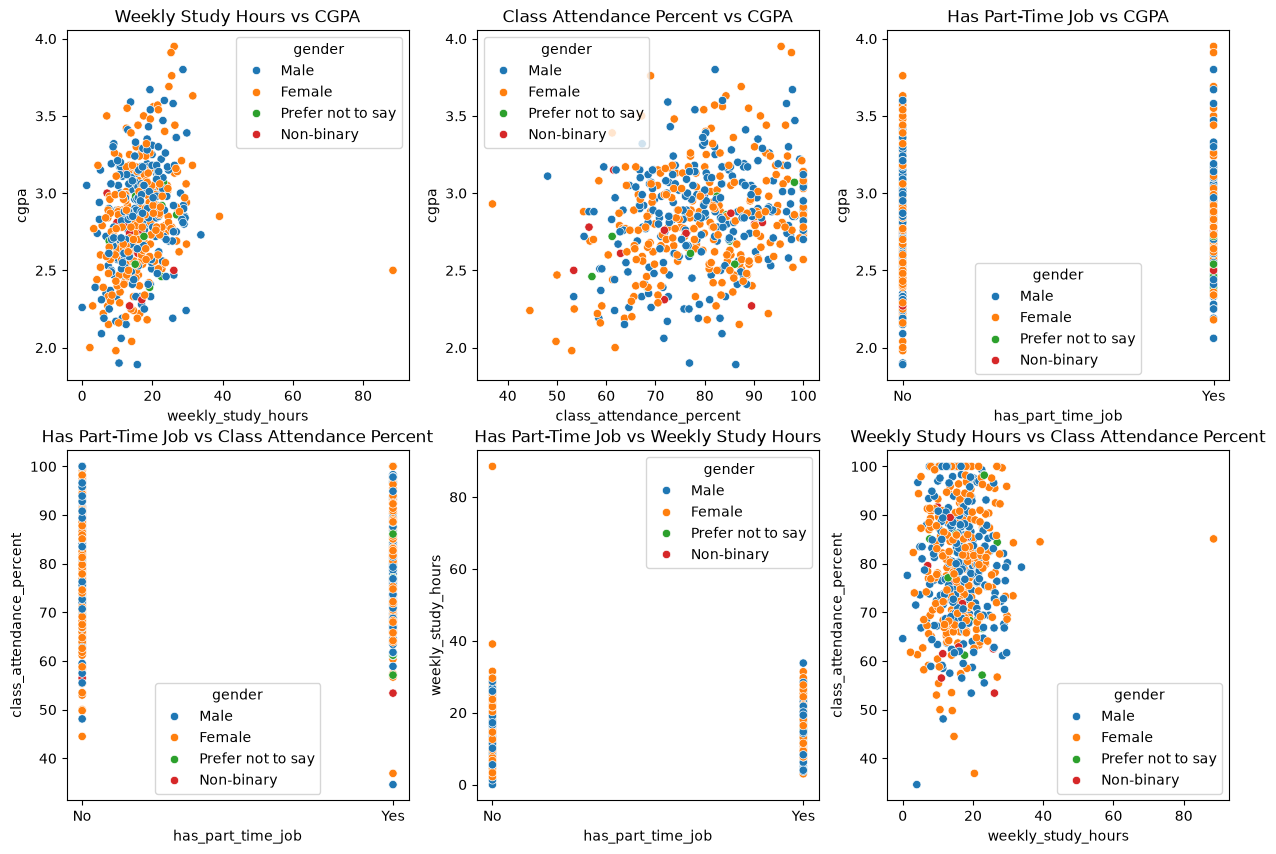

In [14]:
fig, ax = plt.subplots(2,3,figsize=(15, 10))
sns.scatterplot(data=df, x='weekly_study_hours', y='cgpa', hue='gender', ax=ax[0,0])
sns.scatterplot(data=df, x='class_attendance_percent', y='cgpa', hue='gender', ax=ax[0,1])
sns.scatterplot(data=df, x='has_part_time_job', y='cgpa', hue='gender', ax=ax[0,2])

sns.scatterplot(data=df, x='has_part_time_job', y='class_attendance_percent', hue='gender', ax=ax[1,0])
sns.scatterplot(data=df, x='has_part_time_job', y='weekly_study_hours', hue='gender', ax=ax[1,1])
sns.scatterplot(data=df, x='weekly_study_hours', y='class_attendance_percent', hue='gender', ax=ax[1,2])

ax[0,0].set_title('Weekly Study Hours vs CGPA')
ax[0,1].set_title('Class Attendance Percent vs CGPA')
ax[0,2].set_title('Has Part-Time Job vs CGPA')
ax[1,0].set_title('Has Part-Time Job vs Class Attendance Percent')
ax[1,1].set_title('Has Part-Time Job vs Weekly Study Hours')
ax[1,2].set_title('Weekly Study Hours vs Class Attendance Percent')

Chart Analysis: Student Study, Attendance, Part Time Jobs and CGPA 
What is shown in the chart 

This chart has six scatter plots (point-diagrams). Each dot represents a student and gender (Male, Female, Prefer not to say, Non-binary) is separated by color. Four variables are used: 

weekly_study_hours: Weekly study hours 
class_attendance_percent: Percentage of class attendance 
has_part_time_job: Has part time job or not (Yes/No) 
cgpa: cumulative grade point average (approximately 4.0 on a scale) 
Major trends and comparisons 

Study and CGPA: Most students study 10 to 25 hours a week and their CGPA is roughly between 2.3 and 3.5. Those with more study time tend to have slightly higher CGPA, but the relationship is weak and the points are more spread out. 

Attendance and CGPA: CGPA generally tends to increase as attendance increases, but even here the relationship is fairly weak. There is wide variation in CGPA even among students with 80-100% attendance. 

Part time job and CGPA: The spread of CGPA between those with and without jobs is almost the same. There is no clear idea in this chart that CGPA decreases if there is a job. 

Employment and Attendance: Attendance of non-employed students ranges from about 55-100%, and among those with employment is mostly between 60-100%. However, the presence of some of the job holders is very low (about 35-37%), which is noticeable. 

Jobs and Education: This is probably the most useful comparison. Study time ranges from about 3 to 34 hours for those with a job, while the range is much larger (0 to 30-40 hours) for those without a job. That is, employed people seem to study less. 

Studies and Attendance: There is no clear correlation between the two. Most dots coagulate between 10-25 hours and 70-100% presence.

#### Sleep Habits 

columns: 
``chronotype'' mane It determines what time of day you fall asleep, what time you want to wake up, and what time of day you have the most energy and focus. 
* ``early bird'' is a person who gets up early in the morning 
* Night owl 
* `intermediate' is a medium or general type of routine 

`avg_sleep_hours_weekday` Average sleep hours during weekdays (monday to friday) 

`weekend_sleep_delta_hours` means weekday average sleep hours (monday to friday) - chutirdine ghumanur ghoR dhonta (saturdat to sunday)

In [21]:
def decimal_hour_to_time(decimal_hour):
    decimal_hour = decimal_hour % 24
    hours = int(decimal_hour)
    minutes = round((decimal_hour - hours) * 60)

    if minutes == 60:
        hours = (hours + 1) % 24
        minutes = 0
    
    return f"{hours:02d}:{minutes:02d}"

df['avg_badtime'] = df['avg_bedtime_hour'].map(decimal_hour_to_time)


<Axes: xlabel='avg_sleep_hours_weekday', ylabel='cgpa'>

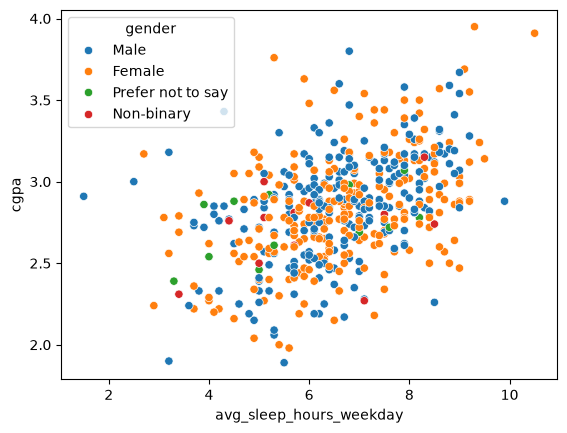

In [26]:
# avg_sleep_hours_weekday vs CGPA (relationship between average sleep hours and CGPA)

sns.scatterplot(data=df, x='avg_sleep_hours_weekday', y='cgpa', hue='gender')

For students whose average weekday sleep hours range between 5 to 8.2/8.3 hours, their CGPA is observed to fall within the 2.3 to 3.2 range. However, as the average sleep hours shift from 5 hours toward 8 hours, this CGPA range narrows and converges toward 3.2. Nevertheless, this trend is weak, and the observations are scattered